# Grover's Algorithm

1. **Oracle:** flips the sign (phase) of the marked state(s).
2. **Diffuser:** reflects all amplitudes about their average, which turns the sign flip into an increase in probability.

For $N = 2^n$ states with $M$ marked, the best number of iterations is

$$k_{\text{opt}} = \left\lfloor \frac{\pi}{4}\sqrt{\frac{N}{M}} \right\rfloor$$

In [3]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
import math
import matplotlib.pyplot as plt



A multi-controlled Z, which we build from a multi-controlled X sandwiched between Hadamards on the last qubit.

In [4]:
def phase_flip_all_ones(qc: QuantumCircuit, n: int) -> None:
    if n == 1:
        qc.z(0)
    else:
        qc.h(n - 1)
        qc.mcx(list(range(n - 1)), n - 1)
        qc.h(n - 1)

The oracle marks answer by giving them a $-1$ phase. For each marked bitstring, apply X gates to every qubit that should be `0`, apply the phase flip and undo the X gates.

In [5]:
def oracle(n: int, marked: list[str]) -> QuantumCircuit:
    qc = QuantumCircuit(n, name="Oracle")
    for target in marked:
        zeros = [i for i, bit in enumerate(reversed(target)) if bit == "0"]
        if zeros:
            qc.x(zeros)
        phase_flip_all_ones(qc, n)
        if zeros:
            qc.x(zeros)
    return qc

Reflects every amplitude about the average amplitude. Marked states, which the oracle pushed below average, end up with larger amplitude. Implemented as Hadamards, X gates, ...

In [6]:
def diffuser(n: int) -> QuantumCircuit:
    qc = QuantumCircuit(n, name="Diffuser")
    qc.h(range(n))
    qc.x(range(n))
    phase_flip_all_ones(qc, n)
    qc.x(range(n))
    qc.h(range(n))
    return qc

## Grover Circuit

In [7]:
def grover_circuit(n: int, marked: list[str], iterations: int) -> QuantumCircuit:
    qc = QuantumCircuit(n)
    qc.h(range(n))
    orc, dif = oracle(n, marked), diffuser(n)
    for _ in range(iterations):
        qc.compose(orc, inplace=True)
        qc.compose(dif, inplace=True)
    return qc

In [8]:
def optimal_iterations(n: int, num_marked: int) -> int:
    return max(1, math.floor(math.pi / 4 * math.sqrt(2**n / num_marked)))

In [9]:
n = 3
marked = ["101"]

assert all(len(m) == n and set(m) <= {"0", "1"} for m in marked)

k_opt = optimal_iterations(n, len(marked))
print(f"Search space size: {2**n}, marked states: {marked}, optimal iterations: {k_opt}")

Search space size: 8, marked states: ['101'], optimal iterations: 2


## 8. Read sucess probabilities

In [10]:
def success_probability(n: int, marked: list[str], iterations: int) -> float:
    probs = Statevector(grover_circuit(n, marked, iterations)).probabilities_dict()
    return sum(probs.get(m, 0.0) for m in marked)

ks = list(range(k_opt + 4))
p_success = [success_probability(n, marked, k) for k in ks]

for k, p in zip(ks, p_success):
    print(f"{k} iterations: {p:.4f}" + ("  <-- optimal" if k == k_opt else ""))

0 iterations: 0.1250
1 iterations: 0.7812
2 iterations: 0.9453  <-- optimal
3 iterations: 0.3301
4 iterations: 0.0122
5 iterations: 0.5480


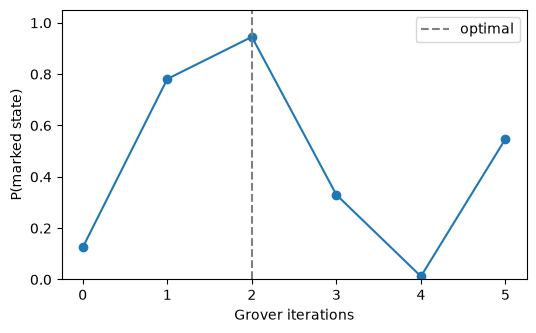

In [11]:
plt.figure(figsize=(6, 3.5))
plt.plot(ks, p_success, marker="o")
plt.axvline(k_opt, linestyle="--", color="gray", label="optimal")
plt.xlabel("Grover iterations")
plt.ylabel("P(marked state)")
plt.ylim(0, 1.05)
plt.legend()
plt.show()

## 9. The circuit

This is the circuit at the optimal iteration count. Each repeated block is one oracle plus one diffuser.

In [12]:
qc = grover_circuit(n, marked, k_opt)
print(qc.draw(fold=120))

     ┌───┐          ┌───┐┌───┐               ┌───┐┌───┐               ┌───┐┌───┐               ┌───┐┌───┐     
q_0: ┤ H ├───────■──┤ H ├┤ X ├────────────■──┤ X ├┤ H ├────────────■──┤ H ├┤ X ├────────────■──┤ X ├┤ H ├─────
     ├───┤┌───┐  │  ├───┤├───┤┌───┐       │  ├───┤├───┤┌───┐       │  ├───┤├───┤┌───┐       │  ├───┤├───┤     
q_1: ┤ H ├┤ X ├──■──┤ X ├┤ H ├┤ X ├───────■──┤ X ├┤ H ├┤ X ├───────■──┤ X ├┤ H ├┤ X ├───────■──┤ X ├┤ H ├─────
     ├───┤├───┤┌─┴─┐├───┤├───┤├───┤┌───┐┌─┴─┐├───┤├───┤├───┤┌───┐┌─┴─┐├───┤├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐
q_2: ┤ H ├┤ H ├┤ X ├┤ H ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ H ├┤ X ├┤ H ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├
     └───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘└───┘


## Histograms

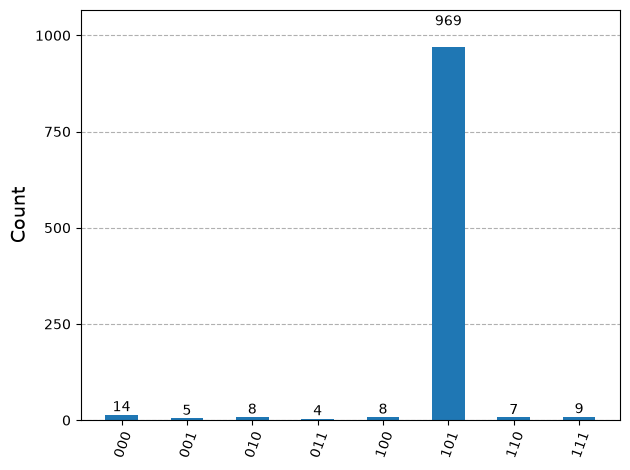

In [13]:
shots = 1024
counts = Statevector(qc).sample_counts(shots)
plot_histogram(counts)

0 iterations: 0.1250
1 iterations: 0.7812
2 iterations: 0.9453  <-- optimal
3 iterations: 0.3301
4 iterations: 0.0122


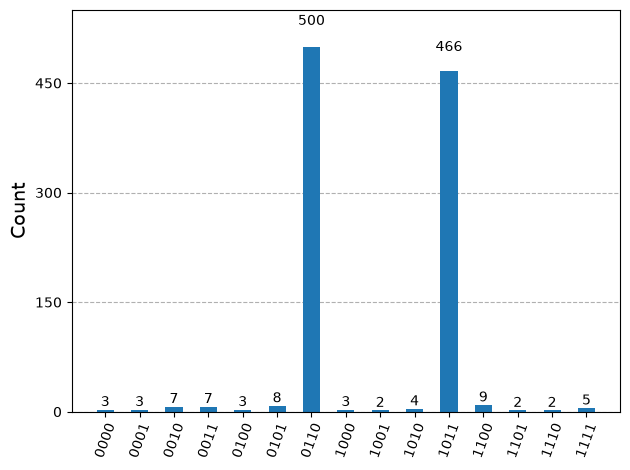

In [14]:
n2, marked2 = 4, ["1011", "0110"]
k2 = optimal_iterations(n2, len(marked2))

for k in range(k2 + 3):
    print(f"{k} iterations: {success_probability(n2, marked2, k):.4f}" + ("  <-- optimal" if k == k2 else ""))

plot_histogram(Statevector(grover_circuit(n2, marked2, k2)).sample_counts(shots))